In [1]:
import numpy as np;
import matplotlib.pyplot as plt;
from PIL import Image;

In [10]:
def planck(waves, T):
    c = 299792458
    k = 1.3806504e-23
    h = 6.62607015e-34

    lambda_m = waves * 1e-9
    return (2 * h * c**2 / (lambda_m**5)) / (np.exp(h * c / (lambda_m * k * T)) - 1);

def gaussian(w, mu, sig1, sig2):
    # Compute Gaussian value for each element in w based on condition
    return np.where(w < mu,
                    np.exp(-0.5 * (w - mu)**2 / (sig1**2)),
                    np.exp(-0.5 * (w - mu)**2 / (sig2**2)))
    

def x_curve(lambda_):
    return 1.056 * gaussian(lambda_, 599.8, 37.9, 31.0) + \
        0.362 * gaussian(lambda_, 442.0, 16.0, 26.7) - \
        0.065 * gaussian(lambda_, 501.1, 20.4, 26.2)


def y_curve(lambda_):
    return 0.821 * gaussian(lambda_, 568.8, 46.9, 40.5) + \
        0.286 * gaussian(lambda_, 530.9, 16.3, 31.1)


def z_curve(lambda_):
    return 1.217 * gaussian(lambda_, 437.0, 11.8, 36.0) + \
        0.681 * gaussian(lambda_, 459.0, 26.0, 13.8)

In [11]:
def XYZtoRGB(xyz):
    M = np.array([
        [0.41847, -0.15866, -0.082835],
        [-0.091169, 0.25243, 0.015708],
        [0.00092090, -0.0025498, 0.17860]
    ])
    return np.dot(M, xyz)

In [17]:
# Parameters
l_step = 1
lambda_ = np.arange(380, 781, l_step)
tex_size = 512

# Temperature and shift range
T = np.linspace(1000, 20000, tex_size)
shift = np.linspace(0.25, 4, tex_size)

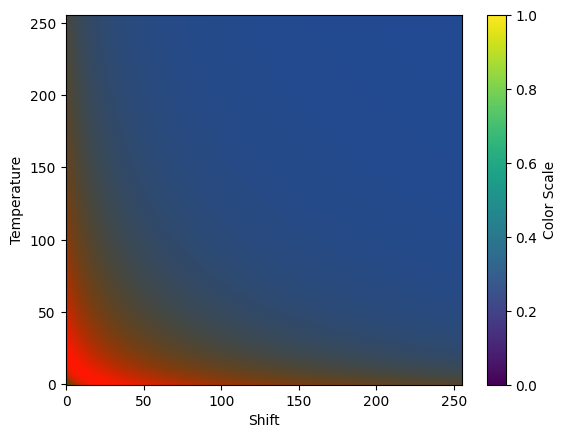

In [19]:
# Output structure
rgb_out = np.zeros((len(T), len(shift), 3))

# Compute radiance and convert to RGB
for n in range(len(T)):
    for m in range(len(shift)):
        radiance = planck(lambda_ * shift[m], T[n])
        X = np.sum(radiance * x_curve(lambda_) * l_step)
        Y = np.sum(radiance * y_curve(lambda_) * l_step)
        Z = np.sum(radiance * z_curve(lambda_) * l_step)
        xyz = np.array([X, Y, Z]) / (X + Y + Z)
        RGB = XYZtoRGB(xyz)
        rgb = RGB / np.max(RGB)
        luminance = np.dot([0.2126, 0.7152, 0.0722], rgb)
        rgb = rgb / luminance
        rgb_out[n, m, :] = rgb

# Normalize and convert to image
rgb_out /= np.max(rgb_out)
rgb_out = np.clip(rgb_out, 0, 1)
rgb_image = (rgb_out * 255).astype(np.uint8)
img = Image.fromarray(rgb_image, 'RGB')
img.save('blackbody.tif')

# Display the image
plt.imshow(rgb_out, aspect='auto', origin='lower')
plt.xlabel('Shift')
plt.ylabel('Temperature')
plt.colorbar(label='Color Scale')
plt.show()